# 01 · Protocol and its implementation

Paper section *Protocol and its implementation* (Eqs. 1–3).

We check, before any simulation of hardware, that

1. the vectors $\lvert r_i\rangle$ of Eq. (2) are orthonormal and $\hat M$ is a rank-$R$ projector,
2. the QR-based unitary completion $\mathcal W$ (Eq. 3) maps $\lvert r_i\rangle\to\lvert i\rangle$,
3. both decompositions (QSD and isometry) reproduce $p(2,k)=k/[2(k+1)]$ **for every input state**
   and leave Bob **exactly** in $\lvert\psi\rangle$ (statevector check),
4. sampling with the ideal `AerSimulator` agrees with theory.

In [1]:
# Load the shared settings and functions (00_core.ipynb must be in the same folder)
%run ./00_core.ipynb

FakeKingston: 156 qubits, native gates ['cz', 'delay', 'id', 'if_else', 'measure', 'measure_2', 'reset', 'rz', 'sx', 'x']
core loaded


## 1. Measurement operator and unitary completion

In [2]:
print(f"{'k':>2} {'R':>3} {'dim':>5} | {'M projector':>11} {'rank M':>6} | {'W unitary':>9} {'W|r_i>=|i>':>10}")
print("-" * 58)
for k in KS:
    M, R = build_r_matrix(k)
    P = M @ M.conj().T                          # POVM element  M_hat = sum_i |r_i><r_i|
    W = unitary_completion(M)
    is_proj = np.allclose(P @ P, P)
    rank = int(round(np.trace(P).real))
    maps_ok = np.allclose(W @ M, np.eye(2 ** (k + 1))[:, :R])
    print(f"{k:>2} {R:>3} {2**(k+1):>5} | {str(is_proj):>11} {rank:>6} | "
          f"{str(np.allclose(W @ W.conj().T, np.eye(2**(k+1)))):>9} {str(maps_ok):>10}")

 k   R   dim | M projector rank M | W unitary W|r_i>=|i>
----------------------------------------------------------
 1   1     4 |        True      1 |      True       True
 2   2     8 |        True      2 |      True       True
 3   3    16 |        True      3 |      True       True
 4   4    32 |        True      4 |      True       True
 5   5    64 |        True      5 |      True       True


## 2. Exactness of the protocol (statevector)

For random inputs $\lvert\psi\rangle$ the success probability must be state independent and the
worst heralded fidelity must be 1, for both decompositions.

In [3]:
print(f"{'k':>2} {'method':<9} | {'p':>8} {'p(2,k)':>8} {'spread':>8} | {'worst F':>12}")
print("-" * 56)
for k in KS:
    for method in METHODS:
        p, spread, worst = exact_check(k, method)
        print(f"{k:>2} {method:<9} | {p:>8.5f} {p_theory(k):>8.5f} {spread:>8.1e} | {worst:>12.10f}")

 k method    |        p   p(2,k)   spread |      worst F
--------------------------------------------------------
 1 qsd       |  0.25000  0.25000  8.3e-17 | 1.0000000000
 1 isometry  |  0.25000  0.25000  1.7e-16 | 1.0000000000
 2 qsd       |  0.33333  0.33333  2.8e-16 | 1.0000000000
 2 isometry  |  0.33333  0.33333  4.4e-16 | 1.0000000000
 3 qsd       |  0.37500  0.37500  3.3e-16 | 1.0000000000
 3 isometry  |  0.37500  0.37500  2.8e-16 | 1.0000000000
 4 qsd       |  0.40000  0.40000  7.2e-16 | 1.0000000000
 4 isometry  |  0.40000  0.40000  1.5e-15 | 1.0000000000
 5 qsd       |  0.41667  0.41667  7.2e-16 | 1.0000000000
 5 isometry  |  0.41667  0.41667  7.9e-15 | 1.0000000000


## 3. Ideal sampling with `AerSimulator`

Same check with shot noise, input $\lvert+\rangle$, using the full tomography circuits.

In [4]:
print(f"{'k':>2} {'method':<9} | {'p (Aer)':>14} {'p(2,k)':>7} | {'F (Aer)':>14}")
print("-" * 56)
for k in KS:
    for method in METHODS:
        r = run_single_qubit(k, method, "ideal", in_state="+")
        print(f"{k:>2} {method:<9} | {r['p']:.4f} ± {r['p_err']:.4f} {p_theory(k):>7.4f} | "
              f"{r['F']:.4f} ± {r['F_err']:.4f}")

 k method    |        p (Aer)  p(2,k) |        F (Aer)
--------------------------------------------------------
 1 qsd       | 0.2511 ± 0.0025  0.2500 | 0.9999 ± 0.0000
 1 isometry  | 0.2528 ± 0.0025  0.2500 | 0.9998 ± 0.0000
 2 qsd       | 0.3335 ± 0.0027  0.3333 | 1.0000 ± 0.0000
 2 isometry  | 0.3318 ± 0.0027  0.3333 | 0.9998 ± 0.0000
 3 qsd       | 0.3800 ± 0.0028  0.3750 | 1.0000 ± 0.0000
 3 isometry  | 0.3750 ± 0.0028  0.3750 | 0.9998 ± 0.0000
 4 qsd       | 0.3988 ± 0.0028  0.4000 | 0.9999 ± 0.0000
 4 isometry  | 0.4035 ± 0.0028  0.4000 | 1.0000 ± 0.0000
 5 qsd       | 0.4226 ± 0.0029  0.4167 | 0.9999 ± 0.0000
 5 isometry  | 0.4161 ± 0.0028  0.4167 | 0.9998 ± 0.0000


## 4. Circuits for $k=2$

The measurement unitary from both decompositions, and the full teleportation circuit
(Bob read out in the $Z$ basis).

qsd: 19 CX, depth 87


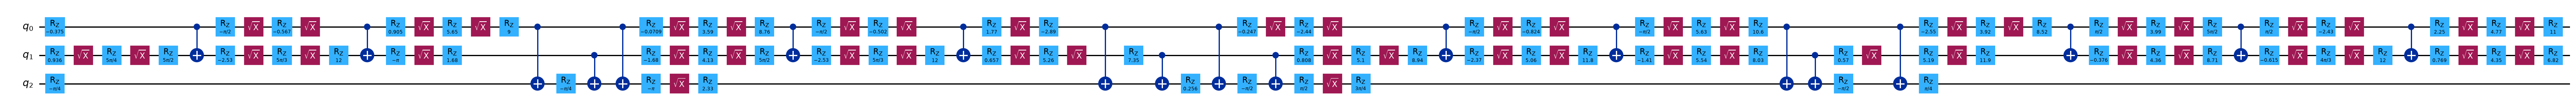

isometry: 10 CX, depth 44


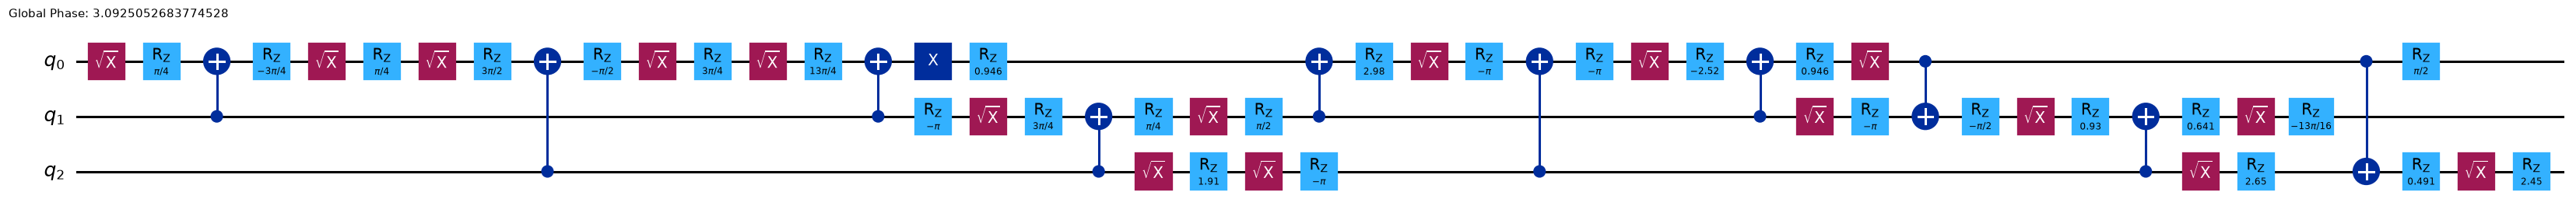

In [7]:
k = 2
for method in METHODS:
    sub, R = measurement_circuit(k, method)
    flat = transpile(sub, basis_gates=["rz", "sx", "x", "cx"], optimization_level=1, seed_transpiler=SEED)
    print(f"{method}: {flat.count_ops().get('cx', 0)} CX, depth {flat.depth()}")
    display(flat.draw("mpl", fold=-1))

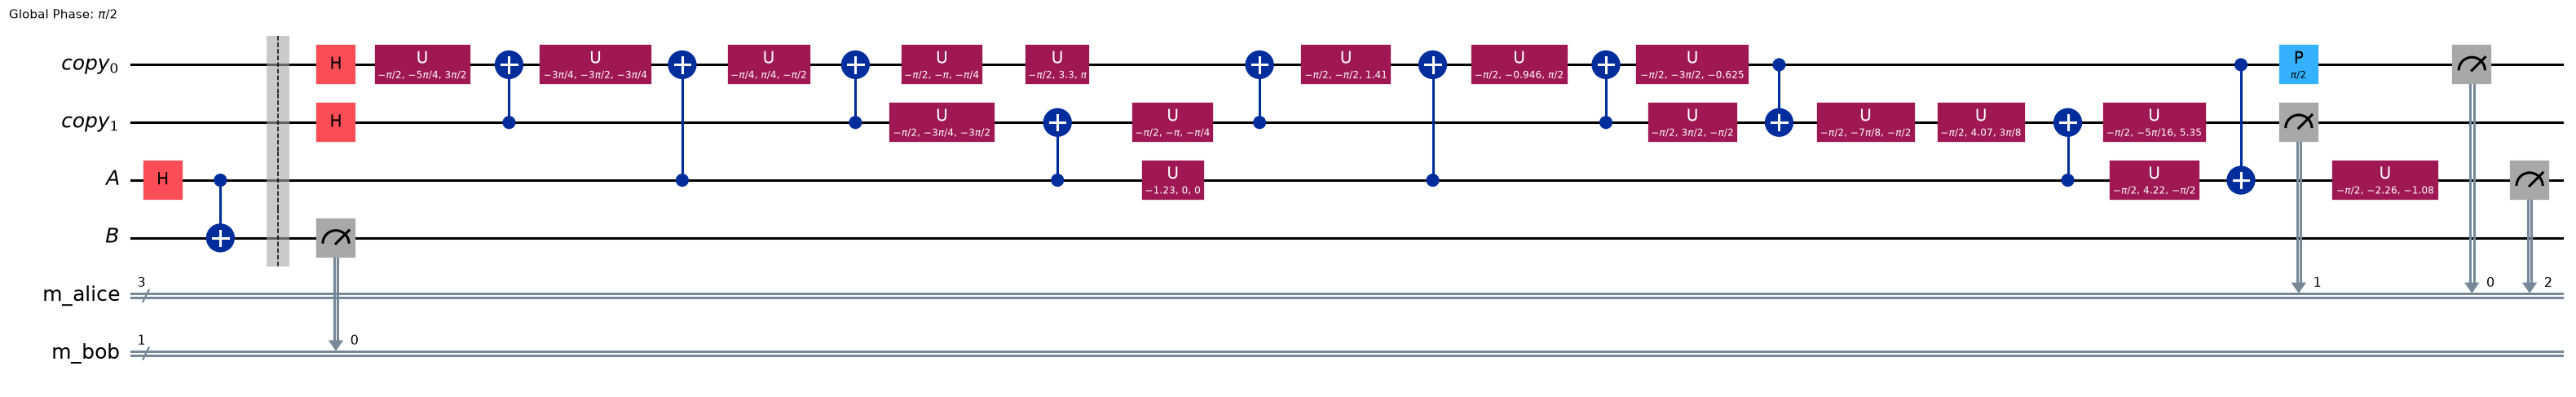

In [9]:
circuits, R = single_qubit_circuits(2, "isometry", in_state="+")
circuits["Z"].draw("mpl", fold=-1)